In [1]:
from skyfield.api import load, wgs84
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import scipy.io as sio
import pytz
import copy
from scipy.optimize import minimize


### Get Candidate Locations for our GS 
```get_candidate_locs``` returns candidate clusters or groups, their centroids (serve as coarse location of GS candidates) 
and the satellites associates with each cluster

Initial number of candidate location clusters: 2382
Possible: 24
Centroid of group  0 : [ 29.19634675 -99.89766455]
Point that minimizes distance to each satellite trajectory : 29.162238769256525 -100.07821591100347
sats in group: ['STARLINK-1017', 'STARLINK-30531', 'STARLINK-5570', 'STARLINK-3550', 'STARLINK-5829', 'STARLINK-2582', 'STARLINK-5999', 'STARLINK-3762', 'STARLINK-30978']
Centroid of group  1 : [  41.80668316 -121.62435425]
Point that minimizes distance to each satellite trajectory : 41.771375194987755 -122.52693867484305
sats in group: ['STARLINK-1283', 'STARLINK-6205', 'STARLINK-6192', 'STARLINK-5419', 'STARLINK-30223', 'STARLINK-6203', 'STARLINK-5416', 'STARLINK-4117', 'STARLINK-30315']
Centroid of group  2 : [  43.37734658 -111.75533912]
Point that minimizes distance to each satellite trajectory : 43.08199263281667 -110.56598655067974
sats in group: ['STARLINK-1449', 'STARLINK-4044', 'STARLINK-31013', 'STARLINK-5824', 'STARLINK-1442', 'STARLINK-5419', 'STARLINK-5844', '

/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satid_blind_identification.py:89: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Centroid of group  4 : [ 41.23279744 -94.18566899]
Point that minimizes distance to each satellite trajectory : 41.252351471051306 -93.9550226566135
sats in group: ['STARLINK-3709', 'STARLINK-1701', 'STARLINK-5378', 'STARLINK-30151', 'STARLINK-3685', 'STARLINK-5773', 'STARLINK-1692', 'STARLINK-30137', 'STARLINK-31032']
Centroid of group  5 : [  32.40739323 -118.10517728]
Point that minimizes distance to each satellite trajectory : 32.7453209508336 -118.68061444922124
sats in group: ['STARLINK-4038', 'STARLINK-2000', 'STARLINK-30954', 'STARLINK-5968', 'STARLINK-5466', 'STARLINK-30964', 'STARLINK-2001', 'STARLINK-5794', 'STARLINK-5592']
Centroid of group  6 : [ 28.47924625 -92.08576498]
Point that minimizes distance to each satellite trajectory : 28.714612491002814 -91.85925967789281
sats in group: ['STARLINK-4144', 'STARLINK-4309', 'STARLINK-6282', 'STARLINK-4312', 'STARLINK-6318', 'STARLINK-4325', 'STARLINK-1449', 'STARLINK-4495', 'STARLINK-1442']
Centroid of group  7 : [  39.97880504 

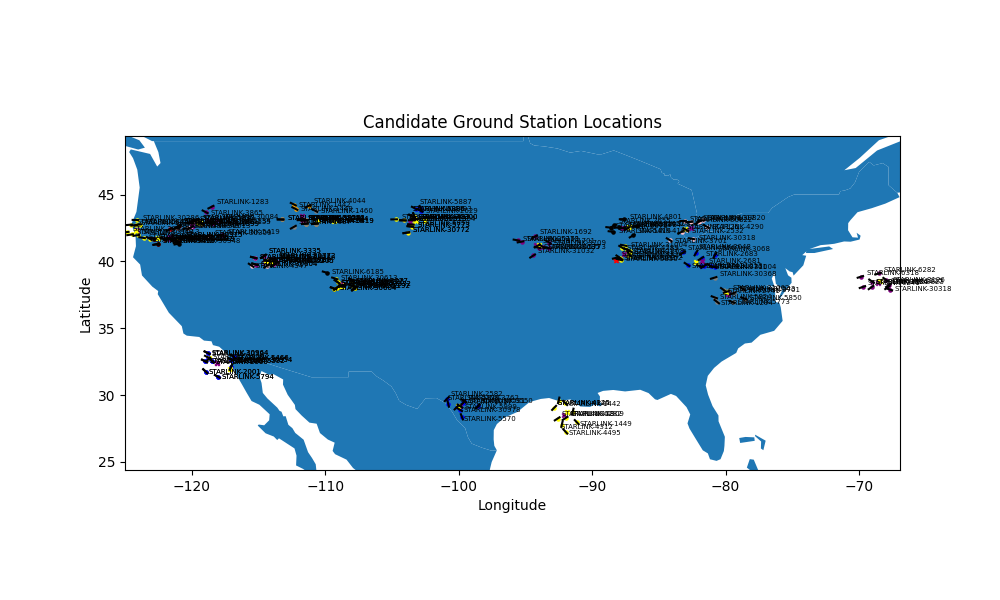

In [26]:
capture_file_path = 'USRP_data/2_5/utctime_5Feb2024_23:58:08_freq_11_325G_bw_2.0M_ts_1707177488.0938272_inrx0.dat'
imu_file_path = '/home/ishani/LeoPNT/USRP_data/2_5/imu_20240205235759.txt'
start_time = datetime.fromtimestamp(float(file_path.split('_')[-2]), tz=pytz.utc)
tle_path = '/home/ishani/LeoPNT/starlink_ofdm/Starloc/5Feb2024_23-58-08/Starlink.tle'
mat = sio.loadmat('/home/ishani/LeoPNT/starlink_ofdm/Starloc/5Feb2024_23-58-08/phase_comp.mat')
tracked_peaks = mat['dopp_track_dict'][0]
time_arr = []
for arr in tracked_peaks:
    time = np.median(np.real(arr[:,0]))
    time_arr.append(time)
## time_arr.append(580.0)
# sort time_arr
time_arr = sorted(time_arr)
%matplotlib widget
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs
gs_groups, coarse_gs, sat_groups = get_candidate_locs(start_time, time_arr, tle_path, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_file_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=15)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Candidate Ground Station Locations')
plt.show()

### Narrowing down to a single candidate GS location
- The idea is to compare the observed phase difference at our receiver/GS with the simulated phase differences at the candidate GS locations. 
- The best match results in a single candidate GS. 
- The satellites that are observed by this GS at time in time array will be the SAT IDs.

##### 1. Simulating to get phase difference for all satellites observed by all ground stations at times in time_arr

In [3]:
## Simulating to get phase differences 
## =================================================
from sat_id import faster_doppler_sim
import pickle
import os

filesavepath = '5Feb2024_23-58-08/satdictlist_for_each_gs.pkl'
load = True
# If kernel restarts or if satdictlist_for_each_gs.pkl is already, load it.
if load == True and os.path.exists(filesavepath):
    with open(filesavepath, 'rb') as f:
        satdictlist_for_each_gs = pickle.load(f)
else:
    # get satellite dopp dict for sats associated with each gs
    capture_start_timestamp = float(file_path.split('_')[-2])
    print("start time: ", datetime.fromtimestamp(capture_start_timestamp, tz=pytz.utc))
    satdictlist_for_each_gs = [{} for i in range(len(coarse_gs))]

    #for each satellite at >75 degree min elevation wrt candidate gs, get the dopp, az, alt, range for about 10 secs around time in time_arr
    for gs_idx,cgs in enumerate(coarse_gs):
        for time in time_arr:
            # cgs = wgs84.latlon(cgs[0], cgs[1])
            # get sat dopp dict 
            date = '_'
            tle_path = tle_path
            fc = 11.325e9
            t_start = capture_start_timestamp + time - 5
            t_stop = capture_start_timestamp + time + 5
            t_step = 1
            gs = cgs
            # get sat dopp dict for this gs 
            sat_dopp_dict, _ = faster_doppler_sim(date, tle_path, fc, t_start, t_stop, t_step, gs, min_ele=75)
            satdictlist_for_each_gs[gs_idx][time] = sat_dopp_dict

    with open(filesavepath, 'wb') as f:
        pickle.dump(satdictlist_for_each_gs, f)

###### 

##### 2. From the simulated alt, az, etc. get the phase differences and the parameters fro each phase difference line (slope and intercept)

In [4]:
# get phase diff params or all sats in each group
from utils.satid_blind_identification import get_phase_diff_params_allsatsingroups
phasediffdict_for_each_gs, phase_diff_param = get_phase_diff_params_allsatsingroups(coarse_gs, satdictlist_for_each_gs, time_arr)

GS 0 Time 11.0250005
GS [ 29.19634675 -99.89766455] Time 11.0250005 Sat: STARLINK-1017
GS [ 29.19634675 -99.89766455] Time 11.0250005 Sat: STARLINK-30986
GS 0 Time 57.8970005
GS [ 29.19634675 -99.89766455] Time 57.8970005 Sat: STARLINK-6236
GS [ 29.19634675 -99.89766455] Time 57.8970005 Sat: STARLINK-30531
GS 0 Time 162.2810005
GS [ 29.19634675 -99.89766455] Time 162.2810005 Sat: STARLINK-5570
GS [ 29.19634675 -99.89766455] Time 162.2810005 Sat: STARLINK-30365
GS 0 Time 212.1210005
GS [ 29.19634675 -99.89766455] Time 212.1210005 Sat: STARLINK-3550
GS 0 Time 254.7930005
GS [ 29.19634675 -99.89766455] Time 254.7930005 Sat: STARLINK-5829
GS [ 29.19634675 -99.89766455] Time 254.7930005 Sat: STARLINK-5877
GS 0 Time 343.4410005
GS [ 29.19634675 -99.89766455] Time 343.4410005 Sat: STARLINK-2582
GS [ 29.19634675 -99.89766455] Time 343.4410005 Sat: STARLINK-30535
GS [ 29.19634675 -99.89766455] Time 343.4410005 Sat: STARLINK-3873
GS 0 Time 394.26800049999997
GS [ 29.19634675 -99.89766455] Time 3

##### 3. Find the GS where the simulated phase difference parameters minimize the distance to the observed phase difference parameters

In [5]:
# find gs where the parameters minimize the difference with the observed phase diff
from utils.satid_blind_identification import find_best_coarse_gs
observed_phase_diff_param = sio.loadmat('5Feb2024_23-58-08/phase_comp_satid.mat')['phase_diff_param'][0]
best_coarse_gs_candidate, best_candidate_idx, min_param_diff_pertime_each_gs, min_param_diff_sat_pertime_each_gs = find_best_coarse_gs(
                                                                                                coarse_gs, 
                                                                                                time_arr,
                                                                                                satdictlist_for_each_gs, 
                                                                                                phase_diff_param, 
                                                                                                observed_phase_diff_param)

Best GS: [ 40.57796894 -87.64195092] Min Param Diff: 0.33176841377681965
All other GS centroids and their respective min param diff:

[ 29.19634675 -99.89766455] 2.069066829120171
[  41.80668316 -121.62435425] 1.4666570878861824
[  43.37734658 -111.75533912] 1.9633745302184649
[ 40.03729283 -81.79407142] 1.0421716191934631
[ 41.23279744 -94.18566899] 1.5909059220480326
[  32.40739323 -118.10517728] 2.1163902211707493
[ 28.47924625 -92.08576498] 1.714633521085727
[  39.97880504 -114.48801137] 2.3101204835761906
[  40.07556833 -114.24707001] 2.3005525823413397
[ 42.5222797  -87.72362015] 1.214614917597386
[  32.42321317 -118.10741949] 2.1164107850112117
[  43.27620343 -103.36737176] 0.7839684295708121
[ 38.38755965 -68.58493323] 2.3708935663456137
[  43.0655929  -111.63979365] 1.848145373685419
[ 40.57796894 -87.64195092] 0.33176841377681965
[  38.29908639 -108.70694789] 1.0097779113435255
[  42.97291136 -103.66387723] 0.9312343166596789
[  43.04955088 -118.76036543] 2.2098159388325276
[

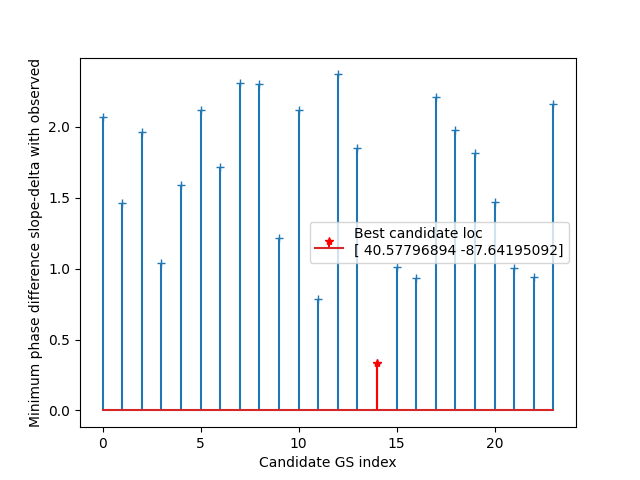

14

In [6]:
plt.figure()
plt.stem(range(len(coarse_gs)), np.sum(min_param_diff_pertime_each_gs, axis=1), markerfmt='+')
plt.stem(best_candidate_idx, np.sum(min_param_diff_pertime_each_gs, axis=1)[best_candidate_idx],markerfmt='*', linefmt='r', label='Best candidate loc\n'+str(best_coarse_gs_candidate))
plt.xlabel('Candidate GS index')
plt.ylabel('Minimum phase difference slope-delta with observed')
plt.legend()
plt.show()
best_candidate_idx

### Save data needed for localization

In [67]:
save_dict = {}
save_dict['real_gs'] = lat_lon_alt_mean
save_dict['centroid_gs'] = best_coarse_gs_candidate
# get farthest gs in the candidate gs_group
d_lat_lon = np.deg2rad(np.array(gs_groups[best_candidate_idx]))-np.deg2rad(lat_lon_alt_mean[:2])
dlat = d_lat_lon[:,0]
dlon = d_lat_lon[:,1]
lat1 = np.deg2rad(np.array(gs_groups[best_candidate_idx]))[:,0]
lat2 = np.deg2rad(lat_lon_alt_mean[0])
a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
dists = 2 * np.arcsin(np.sqrt(a))*6371
farthest_gs_idx = np.argmax(c)
farthest_gs = gs_groups[best_candidate_idx][farthest_gs_idx]
save_dict['farthest_gs_ingroup'] = farthest_gs
#TODO: d0, d1, d2, d3
sio.savemat('5Feb2024_23-58-08/__.mat', save_dict)
